<a href="https://colab.research.google.com/github/Reina-creator/MSSP607-GitHub/blob/main/WeeklyModules/Week09/Assignment09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip -q install requests beautifulsoup4

In [10]:
import requests
import bs4
import time
import shutil

from pathlib import Path
from tempfile import mkdtemp
from urllib.parse import urlparse

In [11]:
category = "cats"

if not category:
    raise ValueError("Please enter a category, such as cats or mountains.")

url = "https://www.flickr.com/services/feeds/photos_public.gne"

parameters = {
    "tags": category,
    "tagmode": "all",
    "format": "json",
    "nojsoncallback": 1
}

res = requests.get(url, params=parameters, timeout=30)
res.raise_for_status()

photo_data = res.json()

print("Search URL:", res.url)
print("Results returned:", len(photo_data["items"]))

Search URL: https://www.flickr.com/services/feeds/photos_public.gne?tags=cats&tagmode=all&format=json&nojsoncallback=1
Results returned: 20


In [12]:
image_urls = []

for photo in photo_data["items"]:
    soup = bs4.BeautifulSoup(
        photo.get("description", ""),
        "html.parser"
    )

    image_elements = soup.find_all("img", src=True)

    for image in image_elements:
        image_url = image["src"]

        if image_url not in image_urls:
            image_urls.append(image_url)

print("Images found:", len(image_urls))

for image_url in image_urls:
    print(image_url)

Images found: 20
https://live.staticflickr.com/65535/55632140669_96e5daab1f_m.jpg
https://live.staticflickr.com/65535/55632312335_d9aecc6dde_m.jpg
https://live.staticflickr.com/65535/55631755776_5cab204aca_m.jpg
https://live.staticflickr.com/65535/55631051416_309faf3eae_m.jpg
https://live.staticflickr.com/65535/55631468390_01bb939e39_m.jpg
https://live.staticflickr.com/65535/55631252704_4a8e003dda_m.jpg
https://live.staticflickr.com/65535/55631183838_88e0be91cb_m.jpg
https://live.staticflickr.com/65535/55631186103_5caca326fd_m.jpg
https://live.staticflickr.com/65535/55631008904_67b585e4bd_m.jpg
https://live.staticflickr.com/65535/55630999569_a43940b9b6_m.jpg
https://live.staticflickr.com/65535/55630989235_e2960e6a99_m.jpg
https://live.staticflickr.com/65535/55628167697_fa815cb14e_m.jpg
https://live.staticflickr.com/65535/55629317229_56bc851282_m.jpg
https://live.staticflickr.com/31337/55628296330_ac763ce082_m.jpg
https://live.staticflickr.com/65535/55627611586_8469270411_m.jpg
https://

In [13]:
download_folder = Path(
    mkdtemp(prefix="flickr_images_", dir="/content")
)

downloaded_files = []
failed_urls = []

for number, image_url in enumerate(image_urls, start=1):
    extension = Path(urlparse(image_url).path).suffix or ".jpg"
    file_path = download_folder / f"image_{number:03d}{extension}"

    try:
        with requests.get(
            image_url,
            timeout=30,
            stream=True
        ) as image_res:

            image_res.raise_for_status()

            content_type = image_res.headers.get("Content-Type", "")

            if not content_type.lower().startswith("image/"):
                raise ValueError("The response is not an image.")

            with open(file_path, "wb") as image_file:
                for chunk in image_res.iter_content(100000):
                    if chunk:
                        image_file.write(chunk)

        downloaded_files.append(file_path)
        print("Downloaded:", file_path.name)

    except (requests.RequestException, OSError, ValueError) as error:
        if file_path.exists():
            file_path.unlink()

        failed_urls.append(image_url)
        print("Download failed:", image_url)
        print("Reason:", error)

    time.sleep(1)

print("\nFinished.")
print("Images found:", len(image_urls))
print("Downloaded:", len(downloaded_files))
print("Failed:", len(failed_urls))
print("Folder:", download_folder)

Downloaded: image_001.jpg
Downloaded: image_002.jpg
Downloaded: image_003.jpg
Downloaded: image_004.jpg
Downloaded: image_005.jpg
Downloaded: image_006.jpg
Downloaded: image_007.jpg
Downloaded: image_008.jpg
Downloaded: image_009.jpg
Downloaded: image_010.jpg
Downloaded: image_011.jpg
Downloaded: image_012.jpg
Downloaded: image_013.jpg
Downloaded: image_014.jpg
Downloaded: image_015.jpg
Downloaded: image_016.jpg
Downloaded: image_017.jpg
Downloaded: image_018.jpg
Downloaded: image_019.jpg
Downloaded: image_020.jpg

Finished.
Images found: 20
Downloaded: 20
Failed: 0
Folder: /content/flickr_images_9lnsgl8k


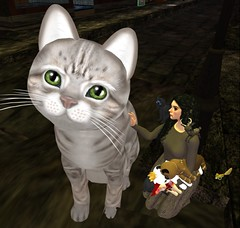

In [14]:
from IPython.display import Image, display

if downloaded_files:
    display(Image(filename=str(downloaded_files[0])))
else:
    print("No images were downloaded.")

In [15]:
from google.colab import files

if downloaded_files:
    zip_path = shutil.make_archive(
        str(download_folder),
        "zip",
        root_dir=str(download_folder)
    )

    files.download(zip_path)
else:
    print("No images available to download.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>